<a href="https://colab.research.google.com/github/ben-chikusa/Ben-Natural-Language-Processing/blob/main/Sentiment_Classification.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences

print("Libraries imported successfully!")
print("TensorFlow version:", tf.__version__)


Libraries imported successfully!
TensorFlow version: 2.21.0


In [ ]:

from google.colab import files

uploaded = files.upload()


Saving sentiment_analysis_assignment_dataset - sentiment_analysis_assignment_dataset.csv to sentiment_analysis_assignment_dataset - sentiment_analysis_assignment_dataset.csv


In [ ]:

import io

filename = next(iter(uploaded))

df = pd.read_csv(io.BytesIO(uploaded[filename]))

print("Dataset shape:", df.shape)
print("\nFirst five rows:")
display(df.head())

print("\nSentiment categories:")
print(df["sentiment"].value_counts())


Dataset shape: (1000, 3)

First five rows:


,id,text,sentiment
0,522,"From my experience, The store is located in th...",Neutral
1,738,"Overall, I purchased the product last week. Ov...",Neutral
2,741,"Overall, The meeting starts at 10 AM tomorrow....",Neutral
3,661,"From my experience, The staff were helpful and...",Positive
4,412,"Personally, The experience was wonderful from ...",Positive



Sentiment categories:
sentiment
Positive    334
Neutral     333
Negative    333
Name: count, dtype: int64


In [ ]:

# Check for missing values
print("Missing values before cleaning:")
print(df.isnull().sum())

# Remove rows with missing review text or sentiment
df = df.dropna(subset=["text", "sentiment"]).copy()

# Convert reviews to strings and remove unnecessary spaces
df["text"] = df["text"].astype(str).str.strip()

# Remove rows with empty review text
df = df[df["text"] != ""].copy()

# Remove duplicate review-and-sentiment pairs
df = df.drop_duplicates(subset=["text", "sentiment"]).copy()

# Reset the row numbering
df = df.reset_index(drop=True)

print("\nDataset shape after cleaning:", df.shape)

print("\nSentiment distribution:")
print(df["sentiment"].value_counts())

print("\nSample cleaned reviews:")
display(df[["text", "sentiment"]].head())


Missing values before cleaning:
id           0
text         0
sentiment    0
dtype: int64

Dataset shape after cleaning: (668, 3)

Sentiment distribution:
sentiment
Negative    231
Positive    224
Neutral     213
Name: count, dtype: int64

Sample cleaned reviews:


,text,sentiment
0,"From my experience, The store is located in th...",Neutral
1,"Overall, I purchased the product last week. Ov...",Neutral
2,"Overall, The meeting starts at 10 AM tomorrow....",Neutral
3,"From my experience, The staff were helpful and...",Positive
4,"Personally, The experience was wonderful from ...",Positive


In [ ]:

# Separate the reviews and sentiment labels
texts = df["text"].astype(str).tolist()
labels = df["sentiment"].astype(str).tolist()

# Convert sentiment categories into numerical labels
label_encoder = LabelEncoder()
y = label_encoder.fit_transform(labels)

print("Sentiment categories:", list(label_encoder.classes_))
print("Numerical labels:", dict(zip(
    label_encoder.classes_,
    label_encoder.transform(label_encoder.classes_)
)))

# Convert words into numerical tokens
vocab_size = 5000

tokenizer = Tokenizer(
    num_words=vocab_size,
    oov_token="<OOV>"
)

tokenizer.fit_on_texts(texts)

sequences = tokenizer.texts_to_sequences(texts)

# Make all review sequences the same length
max_length = 100

X = pad_sequences(
    sequences,
    maxlen=max_length,
    padding="post",
    truncating="post"
)

print("\nNumerical data shape:", X.shape)
print("Label data shape:", y.shape)
print("\nExample review:")
print(texts[0])
print("\nNumerical representation:")
print(X[0])


Sentiment categories: [np.str_('Negative'), np.str_('Neutral'), np.str_('Positive')]
Numerical labels: {np.str_('Negative'): np.int64(0), np.str_('Neutral'): np.int64(1), np.str_('Positive'): np.int64(2)}

Numerical data shape: (668, 100)
Label data shape: (668,)

Example review:
From my experience, The store is located in the city centre. Generally.

Numerical representation:
[11  3  5  2 70 10 71  4  2 72 73 15  0  0  0  0  0  0  0  0  0  0  0  0
  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0
  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0
  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0
  0  0  0  0]


In [ ]:

# Split the data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))

print("\nTraining data shape:", X_train.shape)
print("Testing data shape:", X_test.shape)

print("\nTraining labels shape:", y_train.shape)
print("Testing labels shape:", y_test.shape)


Training samples: 534
Testing samples: 134

Training data shape: (534, 100)
Testing data shape: (134, 100)

Training labels shape: (534,)
Testing labels shape: (134,)


In [ ]:

# Build the neural network model
model = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(max_length,)),

    # Learn numerical representations of words
    tf.keras.layers.Embedding(
        input_dim=vocab_size,
        output_dim=32,
        mask_zero=True
    ),

    # Summarise the word representations
    tf.keras.layers.GlobalAveragePooling1D(),

    # Hidden layer for learning sentiment patterns
    tf.keras.layers.Dense(32, activation="relu"),

    # Reduce overfitting
    tf.keras.layers.Dropout(0.3),

    # Output probabilities for the three sentiment classes
    tf.keras.layers.Dense(
        len(label_encoder.classes_),
        activation="softmax"
    )
])

# Configure the model for training
model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

# Display the model architecture
model.summary()


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding (Embedding)           │ (None, 100, 32)        │       160,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling1d        │ (None, 32)             │             0 │
│ (GlobalAveragePooling1D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 32)             │         1,056 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 3)              │            99 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 161,155 (629.51 KB)

 Trainable params: 161,155 (629.51 KB)

 Non-trainable params: 0 (0.00 B)

In [ ]:

# Train the neural network
history = model.fit(
    X_train,
    y_train,
    epochs=15,
    batch_size=32,
    validation_split=0.2,
    verbose=1
)


Epoch 1/15
14/14 ━━━━━━━━━━━━━━━━━━━━ 2s 40ms/step - accuracy: 0.3630 - loss: 1.0947 - val_accuracy: 0.4953 - val_loss: 1.0875
Epoch 2/15
14/14 ━━━━━━━━━━━━━━━━━━━━ 0s 18ms/step - accuracy: 0.5105 - loss: 1.0792 - val_accuracy: 0.6075 - val_loss: 1.0695
Epoch 3/15
14/14 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - accuracy: 0.5925 - loss: 1.0518 - val_accuracy: 0.6355 - val_loss: 1.0360
Epoch 4/15
14/14 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - accuracy: 0.6815 - loss: 1.0110 - val_accuracy: 0.7757 - val_loss: 0.9890
Epoch 5/15
14/14 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - accuracy: 0.7869 - loss: 0.9474 - val_accuracy: 0.8131 - val_loss: 0.9246
Epoch 6/15
14/14 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - accuracy: 0.8665 - loss: 0.8760 - val_accuracy: 0.8972 - val_loss: 0.8455
Epoch 7/15
14/14 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - accuracy: 0.8852 - loss: 0.7882 - val_accuracy: 0.9065 - val_loss: 0.7570
Epoch 8/15
14/14 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - accuracy: 0.9297 - loss: 0.6976 - val_accuracy: 0.9346 - v

In [ ]:

# Evaluate the model using the testing dataset
test_loss, test_accuracy = model.evaluate(
    X_test,
    y_test,
    verbose=0
)

print("Test Loss:", round(test_loss, 4))
print("Test Accuracy:", round(test_accuracy * 100, 2), "%")


Test Loss: 0.1693
Test Accuracy: 100.0 %


In [ ]:

# Generate predictions for the test reviews
y_prob = model.predict(X_test, verbose=0)

# Select the class with the highest predicted probability
y_pred = np.argmax(y_prob, axis=1)

# Display evaluation metrics for each sentiment
print(classification_report(
    y_test,
    y_pred,
    labels=np.arange(len(label_encoder.classes_)),
    target_names=label_encoder.classes_,
    zero_division=0
))


              precision    recall  f1-score   support

    Negative       1.00      1.00      1.00        46
     Neutral       1.00      1.00      1.00        43
    Positive       1.00      1.00      1.00        45

    accuracy                           1.00       134
   macro avg       1.00      1.00      1.00       134
weighted avg       1.00      1.00      1.00       134



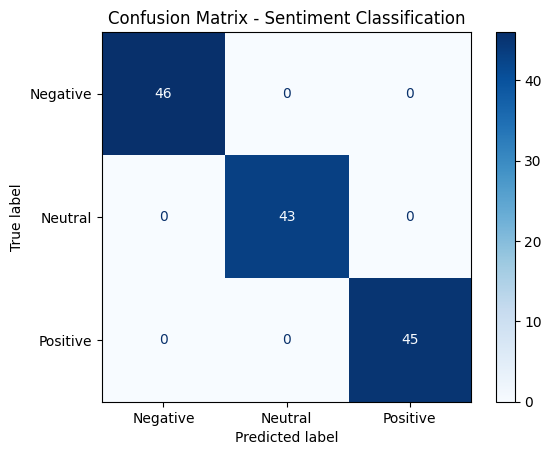

In [ ]:

# Create and display the confusion matrix
cm = confusion_matrix(
    y_test,
    y_pred,
    labels=np.arange(len(label_encoder.classes_))
)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=label_encoder.classes_
)

disp.plot(cmap="Blues", values_format="d")
plt.title("Confusion Matrix - Sentiment Classification")
plt.show()


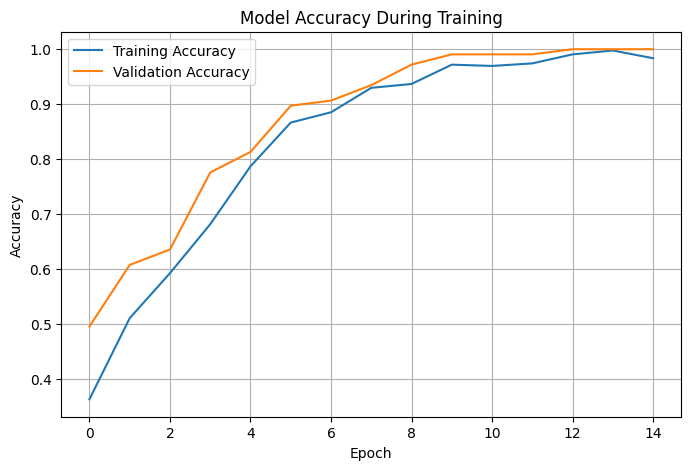

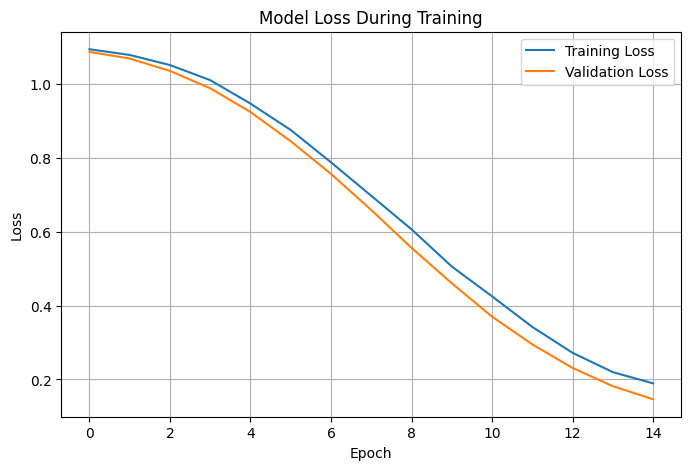

In [12]:

# Plot training and validation accuracy
plt.figure(figsize=(8, 5))
plt.plot(history.history["accuracy"], label="Training Accuracy")
plt.plot(history.history["val_accuracy"], label="Validation Accuracy")
plt.title("Model Accuracy During Training")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.grid(True)
plt.show()

# Plot training and validation loss
plt.figure(figsize=(8, 5))
plt.plot(history.history["loss"], label="Training Loss")
plt.plot(history.history["val_loss"], label="Validation Loss")
plt.title("Model Loss During Training")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.grid(True)
plt.show()


In [13]:

# Enter a new customer review
new_review = ["The product is excellent and I am very happy with it"]

# Convert the review into numerical sequences
new_sequence = tokenizer.texts_to_sequences(new_review)
new_padded = pad_sequences(
    new_sequence,
    maxlen=max_length,
    padding="post",
    truncating="post"
)

# Predict the sentiment
prediction = model.predict(new_padded, verbose=0)
predicted_class = np.argmax(prediction, axis=1)[0]
predicted_sentiment = label_encoder.inverse_transform(
    [predicted_class]
)[0]

print("Customer review:", new_review[0])
print("Predicted sentiment:", predicted_sentiment)
print("Class probabilities:")

for sentiment, probability in zip(
    label_encoder.classes_,
    prediction[0]
):
    print(f"{sentiment}: {probability:.4f}")


Customer review: The product is excellent and I am very happy with it
Predicted sentiment: Positive
Class probabilities:
Negative: 0.0354
Neutral: 0.0011
Positive: 0.9634
